# Bakery Retail Sales Performance & Seasonal Trend Analysis (2023–2024)

**Goal:** assess sales performance and trends over time, across products, stores and promotions, and explain the September revenue peak.

**Dataset:** https://www.kaggle.com/datasets/sdcloud/historical-bakery-sales-dataset — 19,321 line items · 6,576 orders · 731 days · 3 stores · 7 product categories.

**Approach:** validate the data → engineer features → trend & seasonality → driver analysis → recommendations.

## Executive summary

- **Stable year, strong seasonality.** Revenue ≈ 1.33M (2023) → 1.36M (2024), **+2.2%**; profit +2.3%; margin flat at ≈ 42.5%.
- **September is the peak in both years.** Revenue jumps **+32.1% from August to September** in 2023 *and* 2024.
- **The peak coincides with Ganesh Chaturthi and heavier promotion.** Festival-labelled days make up **52% (2023) and 59% (2024)** of September revenue; the share of promoted line items nearly doubles (≈ 48% / 44% vs ≈ 27% / 26% in other months).
- **Bigger baskets, not just more orders.** Units per order rise ≈ 25–28% in September, while revenue per unit falls (≈ −4% in 2023, ≈ −11% in 2024).
- **The lift is broad-based.** All 7 categories and all 3 stores grow from August to September in both years.
- **The festival calendar moves.** Diwali falls in November 2023 but straddles October–November 2024, which explains the October/November mismatch between the two years.
- **Promotion has a margin cost.** September margin is ≈ 1.8 pp lower (41.0% / 40.8% vs 42.7%), yet absolute profit is still well above a normal month.
- **Data-quality highlight.** Stock columns (`Units_Produced`, `Units_Sold`, `Unsold_Units`, `Waste_Pct`) are **group-level aggregates** (Date × Store × Product) repeated on every transaction row; summing them row-wise inflates totals.

> Numbers above come from the analysis run; re-check them against the outputs below after a final *Restart & Run All*.

## Contents
1. Setup & data loading
2. Data overview
3. Data quality checks
4. Feature engineering
5. Overall performance
6. Monthly trend & seasonality
7. Deep dive: the September peak
8. Festival calendar effect
9. Promotion & margin
10. Category & store performance
11. Waste & stock (group level)
12. Conclusions & recommendations
13. Limitations

## 1. Setup & data loading

In [1]:
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 5)

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

In [2]:
csv_files = glob.glob("/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv", recursive=True)
print(csv_files)

DATA_PATH = csv_files[0]  # adjust if the dataset contains more than one CSV
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df.shape

['/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv']


(19321, 40)

## 2. Data overview

Understanding the **granularity** first: one row is a *line item* (one product within one order), not a whole order.

In [3]:
n_orders = df["Order_ID"].nunique()
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Date range: {df['Date'].min().date()} → {df['Date'].max().date()} ({df['Date'].nunique()} distinct days)")
print(f"Orders: {n_orders:,} | Customers: {df['Customer_ID'].nunique():,} | Stores: {df['Store_ID'].nunique()} | Products: {df['Product'].nunique()}")
print(f"Average line items per order: {len(df) / n_orders:.2f}")
df.head(3).T

Rows: 19,321 | Columns: 40
Date range: 2023-01-01 → 2024-12-31 (731 distinct days)
Orders: 6,576 | Customers: 500 | Stores: 3 | Products: 35
Average line items per order: 2.94


,0,1,2
Order_ID,ORD00001,ORD00001,ORD00002
Customer_ID,CUST0328,CUST0328,CUST0016
Customer_Age,46,46,21
Customer_Gender,Other,Other,Female
Customer_Segment,Young Professional,Young Professional,Student
Loyalty_Member,Yes,Yes,No
Date,2023-01-01 00:00:00,2023-01-01 00:00:00,2023-01-01 00:00:00
Year,2023,2023,2023
Month,1,1,1
Day,1,1,1


## 3. Data quality checks

Checks: missing values, duplicates, internal consistency of the price/profit formulas, and how the stock columns behave.

In [4]:
missing = df.isna().sum()
print("Missing values:")
print(missing[missing > 0])
print("Duplicated rows:", df.duplicated().sum())

# Missing Festival / Promotion_Type mean "no festival" / "no promotion", so they become an explicit category.
df["Festival"] = df["Festival"].fillna("None")
df["Promotion_Type"] = df["Promotion_Type"].fillna("None")

Missing values:
Festival          16006
Promotion_Type    13826
dtype: int64
Duplicated rows: 0


In [5]:
checks = pd.DataFrame({
    "Selling_Price = Unit_Price × (1 − Discount%)": np.isclose(
        df["Selling_Price"], df["Unit_Price"] * (1 - df["Discount_Percentage"] / 100), atol=0.02),
    "Total_Bill = Quantity × Selling_Price": np.isclose(
        df["Total_Bill"], df["Quantity"] * df["Selling_Price"], atol=0.05),
    "Profit = (Selling_Price − Cost_Price) × Quantity": np.isclose(
        df["Profit"], (df["Selling_Price"] - df["Cost_Price"]) * df["Quantity"], atol=0.05),
    "Unsold_Units = Units_Produced − Units_Sold": (df["Units_Produced"] - df["Units_Sold"]).eq(df["Unsold_Units"]),
    "Day_of_Week matches Date": df["Date"].dt.day_name().eq(df["Day_of_Week"]),
})
checks.mean().mul(100).round(2).rename("% rows consistent").to_frame()

,% rows consistent
Selling_Price = Unit_Price × (1 − Discount%),100.00
Total_Bill = Quantity × Selling_Price,100.00
Profit = (Selling_Price − Cost_Price) × Quantity,100.00
Unsold_Units = Units_Produced − Units_Sold,100.00
Day_of_Week matches Date,100.00


**Reading the result:** price, bill and profit formulas hold for every row, so `Total_Bill` and `Profit` can be summed safely at line level.

Next: which columns are order-level, and are the stock columns really row-level?

In [6]:
per_order = df.groupby("Order_ID")[["Customer_Rating", "Store_ID", "Time"]].nunique().max()
print("Max distinct values within one order (1 = order-level attribute):")
print(per_order)
print()
print("Units_Sold == Quantity at row level:", f"{(df['Units_Sold'] == df['Quantity']).mean():.1%}")

key = ["Date", "Store_ID", "Product"]
g_check = df.groupby(key).agg(
    n_rows=("Order_ID", "size"),
    sum_qty=("Quantity", "sum"),
    produced_nuniq=("Units_Produced", "nunique"),
    sold_nuniq=("Units_Sold", "nunique"),
    sold=("Units_Sold", "first"),
)
print(f"\nGroups (Date × Store × Product): {len(g_check):,} vs rows: {len(df):,}")
print(f"Units_Sold identical within a group      : {(g_check['sold_nuniq'] == 1).mean():.1%}")
print(f"Units_Sold == sum(Quantity) within group : {(g_check['sold'] == g_check['sum_qty']).mean():.1%}")
print(f"Units_Produced identical within a group  : {(g_check['produced_nuniq'] == 1).mean():.1%}")

Max distinct values within one order (1 = order-level attribute):
Customer_Rating    1
Store_ID           1
Time               1
dtype: int64

Units_Sold == Quantity at row level: 73.3%

Groups (Date × Store × Product): 16,563 vs rows: 19,321
Units_Sold identical within a group      : 100.0%
Units_Sold == sum(Quantity) within group : 100.0%
Units_Produced identical within a group  : 96.7%


**Key finding:** `Units_Sold` equals the *total* quantity of its Date × Store × Product group, and is repeated on every transaction row of that group. The same applies to `Units_Produced`, `Unsold_Units` and `Waste_Pct`.
**Rule for the rest of the notebook:** sales metrics (`Quantity`, `Total_Bill`, `Profit`) are summed at line level; stock/waste metrics are only analysed on the **group-level table** (Section 11).

A small share of groups (≈ 3.3%) shows different `Units_Produced` values across rows. This is documented as a limitation rather than silently corrected.

,count,mean,std,min,25%,50%,75%,max
Quantity,"19,321.00",2.23,1.78,1.00,1.00,2.00,3.00,20.00
Total_Bill,"19,321.00",139.27,157.77,13.12,52.12,82.80,146.54,"1,885.96"
Profit,"19,321.00",59.20,65.24,-0.55,20.69,36.76,65.92,767.60
Waste_Pct,"19,321.00",34.12,12.73,4.20,25.00,33.30,50.00,50.00
Discount_Percentage,"19,321.00",4.35,6.79,0.00,0.00,0.00,7.50,30.00


Rows with negative profit: 7


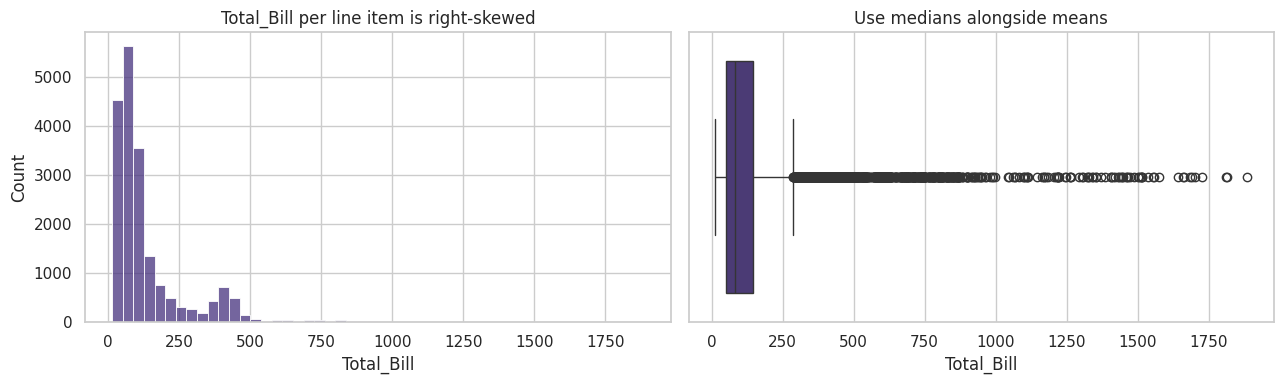

In [7]:
display(df[["Quantity", "Total_Bill", "Profit", "Waste_Pct", "Discount_Percentage"]].describe().T)
print("Rows with negative profit:", (df["Profit"] < 0).sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Total_Bill"], bins=50, ax=ax[0])
ax[0].set_title("Total_Bill per line item is right-skewed")
sns.boxplot(x=df["Total_Bill"], ax=ax[1])
ax[1].set_title("Use medians alongside means")
plt.tight_layout()
plt.show()

## 4. Feature engineering

In [8]:
df["YearMonth"] = df["Date"].dt.to_period("M")
df["Gross_Revenue"] = df["Unit_Price"] * df["Quantity"]                 # before discount
df["Discount_Amount"] = df["Gross_Revenue"] - df["Total_Bill"]
df["Is_Promo"] = df["Promotion_Applied"].eq("Yes")
df["Is_Festival"] = df["Festival"].ne("None")
df["Is_Sep"] = df["Month"].eq(9)


def kpi_table(by):
    """Core KPIs for any grouping. Margin and AOV are ratios of sums, never averages of ratios."""
    t = df.groupby(by, observed=True).agg(
        Revenue=("Total_Bill", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique"),
        Units=("Quantity", "sum"),
        Days=("Date", "nunique"),
    )
    t["Margin_%"] = t["Profit"] / t["Revenue"] * 100
    t["AOV"] = t["Revenue"] / t["Orders"]
    t["Units_per_Order"] = t["Units"] / t["Orders"]
    t["Rev_per_Unit"] = t["Revenue"] / t["Units"]
    t["Rev_per_Day"] = t["Revenue"] / t["Days"]
    return t


# Order-level table (one row per order) for order-level questions
orders = (df.groupby("Order_ID")
            .agg(Date=("Date", "first"), Store_ID=("Store_ID", "first"), Customer_ID=("Customer_ID", "first"),
                 Revenue=("Total_Bill", "sum"), Profit=("Profit", "sum"), Units=("Quantity", "sum"),
                 Items=("Product", "count"), Rating=("Customer_Rating", "first"))
            .reset_index())
orders.head()

,Order_ID,Date,Store_ID,Customer_ID,Revenue,Profit,Units,Items,Rating
0,ORD00001,2023-01-01,ST02,CUST0328,397.65,181.44,9,2,4
1,ORD00002,2023-01-01,ST03,CUST0016,553.38,193.64,11,3,4
2,ORD00003,2023-01-01,ST02,CUST0389,34.92,14.15,1,1,5
3,ORD00004,2023-01-01,ST02,CUST0053,"1,133.79",537.14,7,2,5
4,ORD00005,2023-01-01,ST01,CUST0454,490.92,195.37,11,4,3


## 5. Overall performance

In [9]:
yearly = kpi_table("Year")
yearly["Revenue_YoY_%"] = yearly["Revenue"].pct_change() * 100
yearly["Profit_YoY_%"] = yearly["Profit"].pct_change() * 100
yearly

,Revenue,Profit,Orders,Units,Days,Margin_%,AOV,Units_per_Order,Rev_per_Unit,Rev_per_Day,Revenue_YoY_%,Profit_YoY_%
Year,,,,,,,,,,,,
2023,"1,330,580.05","565,414.47",3208,21360,365,42.49,414.77,6.66,62.29,"3,645.42",NaN,NaN
2024,"1,360,226.00","578,323.08",3368,21667,366,42.52,403.87,6.43,62.78,"3,716.46",2.23,2.28


**Takeaway:** 2024 is only slightly above 2023 (revenue ≈ +2.2%, profit ≈ +2.3%) with an unchanged margin. The interesting story is *within* the year, not between years.

## 6. Monthly trend & seasonality

In [10]:
monthly = kpi_table(["Year", "Month"])
monthly["Revenue_MoM_%"] = monthly.groupby(level="Year")["Revenue"].pct_change() * 100
monthly

Revenue    Profit  Orders  Units  Days  Margin_%    AOV  \
Year Month                                                              
2023 1     115,574.77 48,227.52     282   1870    31     41.73 409.84   
     2      86,207.93 38,212.33     236   1452    28     44.33 365.29   
     3     100,798.92 43,348.61     265   1652    31     43.01 380.37   
     4     115,348.34 48,375.45     274   1766    30     41.94 420.98   
     5     102,209.33 44,589.19     250   1558    31     43.63 408.84   
     6     106,064.32 46,454.44     254   1676    30     43.80 417.58   
     7      87,839.27 38,623.58     245   1488    31     43.97 358.53   
     8     108,449.40 46,541.10     279   1797    31     42.92 388.71   
     9     143,285.02 58,710.47     301   2476    30     40.97 476.03   
     10    110,439.20 46,104.17     272   1806    31     41.75 406.03   
     11    131,384.23 54,329.76     276   1868    30     41.35 476.03   
     12    122,979.32 51,897.85     274   1951    31     42.20 448.83   
2024 1     136,307.05 57,222.44     306   2186    31     41.98 445.45   
     2      96,067.86 42,080.81     240   1560    29     43.80 400.28   
     3     117,755.62 49,569.12     302   1854    31     42.09 389.92   
     4     113,010.76 47,825.45     276   1878    30     42.32 409.46   
     5     104,352.78 45,099.96     270   1555    31     43.22 386.49   
     6      89,075.96 38,731.54     242   1448    30     43.48 368.08   
     7      97,273.15 42,585.55     289   1693    31     43.78 336.59   
     8     103,563.62 43,881.34     275   1594    31     42.37 376.59   
     9     136,843.26 55,882.92     325   2363    30     40.84 421.06   
     10    136,221.15 56,450.86     303   1979    31     41.44 449.57   
     11    114,211.67 48,752.54     263   1683    30     42.69 434.26   
     12    115,543.12 50,240.55     277   1874    31     43.48 417.12   

            Units_per_Order  Rev_per_Unit  Rev_per_Day  Revenue_MoM_%  
Year Month                                                             
2023 1                 6.63         61.80     3,728.22            NaN  
     2                 6.15         59.37     3,078.85         -25.41  
     3                 6.23         61.02     3,251.58          16.93  
     4                 6.45         65.32     3,844.94          14.43  
     5                 6.23         65.60     3,297.08         -11.39  
     6                 6.60         63.28     3,535.48           3.77  
     7                 6.07         59.03     2,833.52         -17.18  
     8                 6.44         60.35     3,498.37          23.46  
     9                 8.23         57.87     4,776.17          32.12  
     10                6.64         61.15     3,562.55         -22.92  
     11                6.77         70.33     4,379.47          18.97  
     12                7.12         63.03     3,967.07          -6.40  
2024 1                 7.14         62.35     4,397.00            NaN  
     2                 6.50         61.58     3,312.68         -29.52  
     3                 6.14         63.51     3,798.57          22.58  
     4                 6.80         60.18     3,767.03          -4.03  
     5                 5.76         67.11     3,366.22          -7.66  
     6                 5.98         61.52     2,969.20         -14.64  
     7                 5.86         57.46     3,137.84           9.20  
     8                 5.80         64.97     3,340.76           6.47  
     9                 7.27         57.91     4,561.44          32.13  
     10                6.53         68.83     4,394.23          -0.45  
     11                6.40         67.86     3,807.06         -16.16  
     12                6.77         61.66     3,727.20           1.17

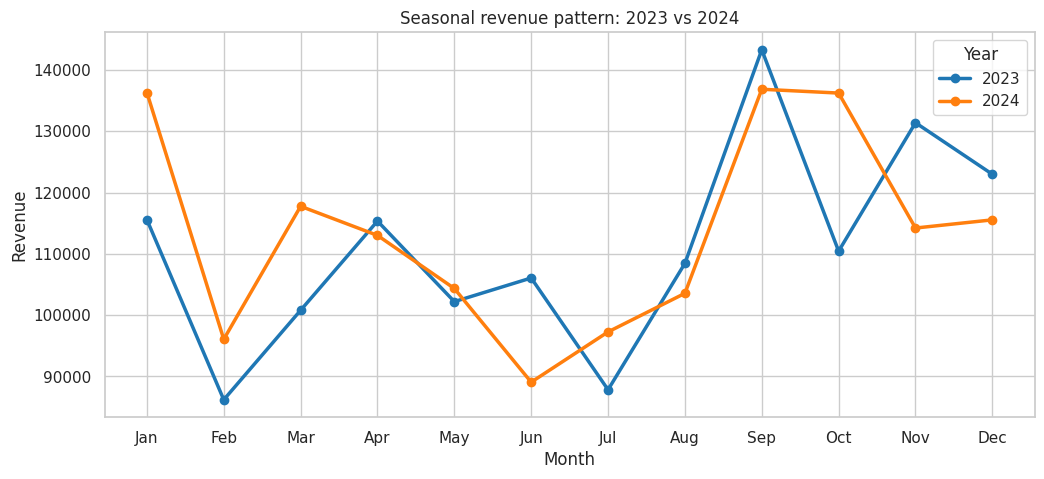

In [11]:
pivot = monthly["Revenue"].unstack("Year")

ax = pivot.plot(marker="o", linewidth=2.5, color=["#1f77b4", "#ff7f0e"])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.set_title("Seasonal revenue pattern: 2023 vs 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.legend(title="Year")
plt.show()

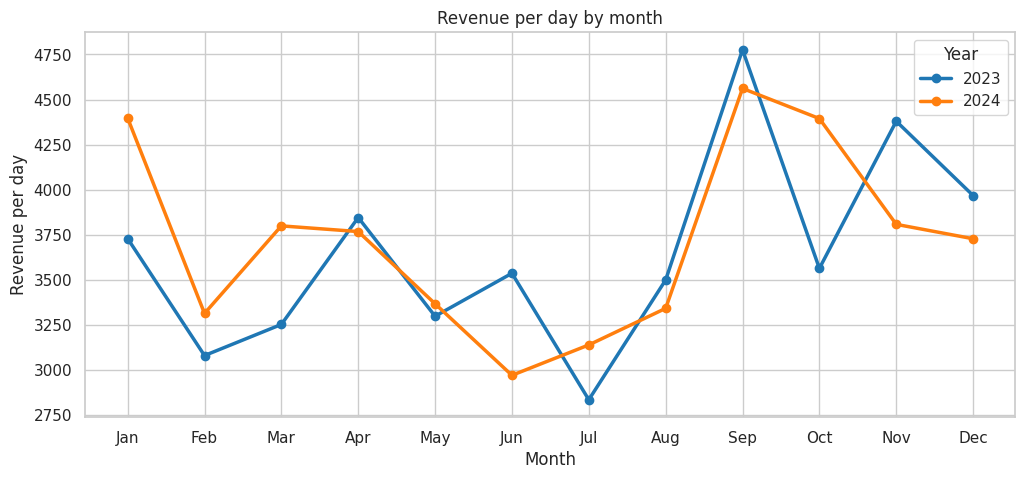

Year,2023,2024,YoY_%
Jan,"115,574.77","136,307.05",17.94
Feb,"86,207.93","96,067.86",11.44
Mar,"100,798.92","117,755.62",16.82
Apr,"115,348.34","113,010.76",-2.03
May,"102,209.33","104,352.78",2.10
Jun,"106,064.32","89,075.96",-16.02
Jul,"87,839.27","97,273.15",10.74
Aug,"108,449.40","103,563.62",-4.51
Sep,"143,285.02","136,843.26",-4.50
Oct,"110,439.20","136,221.15",23.34


In [12]:
# Months have different lengths, so also compare revenue per day
pivot_day = monthly["Rev_per_Day"].unstack("Year")

ax = pivot_day.plot(marker="o", linewidth=2.5, color=["#1f77b4", "#ff7f0e"])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.set_title("Revenue per day by month")
ax.set_ylabel("Revenue per day")
plt.show()

yoy = pivot.copy()
yoy["YoY_%"] = (yoy[2024] / yoy[2023] - 1) * 100
yoy.index = MONTHS
yoy

**Observations**
- September is the peak in both years; Jun–Jul is the weakest stretch of the first half.
- Only **two annual cycles** are available, so this is an *indication* of seasonality, not proof.
- October–December and January differ noticeably between the years. Section 8 shows that the festival calendar explains much of this.

## 7. Deep dive: the September peak

Revenue = orders × average order value (AOV). Which of the two moved, and how did basket size and price per unit change?

Revenue  Orders  Units    AOV  Units_per_Order  Rev_per_Unit  \
Year Month                                                                   
2023 8     108,449.40     279   1797 388.71             6.44         60.35   
     9     143,285.02     301   2476 476.03             8.23         57.87   
2024 8     103,563.62     275   1594 376.59             5.80         64.97   
     9     136,843.26     325   2363 421.06             7.27         57.91   

            Rev_per_Day  
Year Month               
2023 8         3,498.37  
     9         4,776.17  
2024 8         3,340.76  
     9         4,561.44

Change August → September (%)


,Revenue,Orders,Units,AOV,Units_per_Order,Rev_per_Unit,Rev_per_Day
Year,,,,,,,
2023,32.10,7.90,37.80,22.50,27.70,-4.10,36.50
2024,32.10,18.20,48.20,11.80,25.40,-10.90,36.50


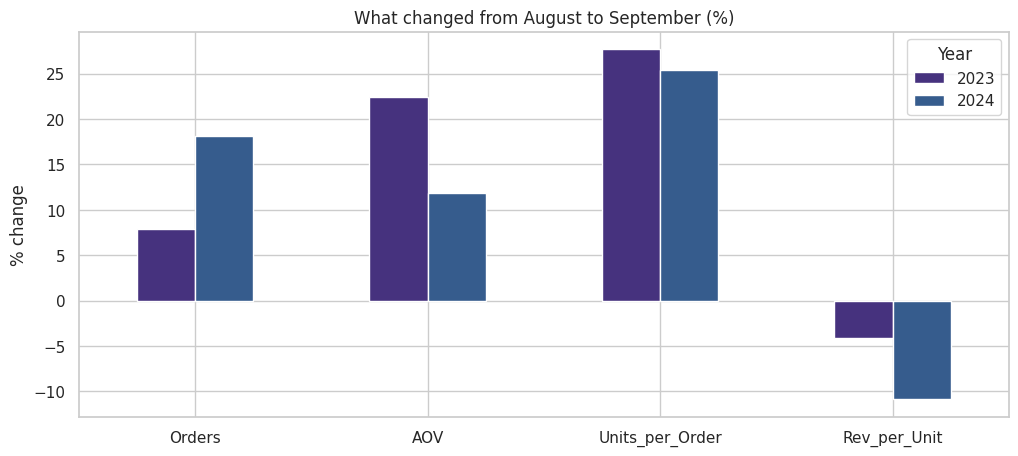

In [13]:
cols = ["Revenue", "Orders", "Units", "AOV", "Units_per_Order", "Rev_per_Unit", "Rev_per_Day"]
aug_sep = monthly.loc[(slice(None), [8, 9]), cols]
display(aug_sep)

chg = (aug_sep.xs(9, level="Month") / aug_sep.xs(8, level="Month") - 1) * 100
print("Change August → September (%)")
display(chg.round(1))

chg[["Orders", "AOV", "Units_per_Order", "Rev_per_Unit"]].T.plot.bar(rot=0)
plt.title("What changed from August to September (%)")
plt.ylabel("% change")
plt.show()

**Reading:** revenue grows by the same ≈ 32% in both years, but the mix differs (2023: mostly higher AOV; 2024: more orders *and* higher AOV). What is consistent is the **larger basket** (more units per order) at a **lower revenue per unit**.

In [14]:
# Festival contribution to September revenue
sep = df[df["Month"] == 9]
fest_rev = sep.groupby(["Festival", "Year"])["Total_Bill"].sum().unstack("Year")
fest_share = fest_rev / fest_rev.sum() * 100
display(pd.concat({"Revenue": fest_rev, "Share_%": fest_share}, axis=1))

# Promotion intensity: September vs other months
promo_sep = df.groupby(["Year", "Is_Sep"]).agg(
    Promo_Share=("Is_Promo", "mean"),
    Avg_Discount_Pct=("Discount_Percentage", "mean"),
)
promo_sep.index = promo_sep.index.set_levels(["Other months", "September"], level="Is_Sep")
promo_sep

Revenue           Share_%      
Year                  2023      2024    2023  2024
Festival                                          
Ganesh Chaturthi 74,292.22 80,286.29   51.85 58.67
None             68,992.80 56,556.97   48.15 41.33

Promo_Share  Avg_Discount_Pct
Year Is_Sep                                     
2023 Other months         0.27              4.20
     September            0.48              6.87
2024 Other months         0.26              3.95
     September            0.44              6.59

In [15]:
# Which categories and stores drive August → September?
def aug_sep_change(dim):
    p = (df[df["Month"].isin([8, 9])]
         .pivot_table(index=dim, columns=["Year", "Month"], values="Total_Bill", aggfunc="sum"))
    out = {}
    for y in (2023, 2024):
        t = pd.DataFrame({"Aug": p[(y, 8)], "Sep": p[(y, 9)]})
        t["Change"] = t["Sep"] - t["Aug"]
        t["Change_%"] = (t["Sep"] / t["Aug"] - 1) * 100
        out[y] = t
    return pd.concat(out, axis=1)


display(aug_sep_change("Category"))
display(aug_sep_change("Store_ID"))

2023                                   2024            \
                      Aug       Sep    Change Change_%       Aug       Sep   
Category                                                                     
Beverages        8,811.79 12,512.50  3,700.71    42.00  8,090.22 12,523.98   
Bread & Daily    6,826.56  9,855.42  3,028.86    44.37  5,298.78  9,198.58   
Cakes           36,443.26 46,471.38 10,028.12    27.52 35,737.32 41,669.14   
Dairy & Spreads 15,193.56 18,506.42  3,312.86    21.80 14,349.85 24,382.92   
Indian Bakery   23,803.57 35,748.47 11,944.90    50.18 24,432.53 30,327.34   
Pastry & Sweet  13,412.02 15,088.76  1,676.74    12.50 10,658.73 12,541.99   
Savoury Bakery   3,958.64  5,102.07  1,143.43    28.88  4,996.19  6,199.31   

                                    
                   Change Change_%  
Category                            
Beverages        4,433.76    54.80  
Bread & Daily    3,899.80    73.60  
Cakes            5,931.82    16.60  
Dairy & Spreads 10,033.07    69.92  
Indian Bakery    5,894.81    24.13  
Pastry & Sweet   1,883.26    17.67  
Savoury Bakery   1,203.12    24.08

2023                                   2024                      \
               Aug       Sep    Change Change_%       Aug       Sep    Change   
Store_ID                                                                        
ST01     37,643.49 49,494.56 11,851.07    31.48 35,834.57 46,157.26 10,322.69   
ST02     40,521.86 46,649.31  6,127.45    15.12 26,502.25 44,195.51 17,693.26   
ST03     30,284.05 47,141.15 16,857.10    55.66 41,226.80 46,490.49  5,263.69   

                   
         Change_%  
Store_ID           
ST01        28.81  
ST02        66.76  
ST03        12.77

**Reading**
- All categories grow in both years, so the lift is **broad-based**. Bread & Daily and Beverages grow fastest in relative terms; Cakes and Indian Bakery are the largest absolute contributors in 2023, Dairy & Spreads in 2024. Pastry & Sweet grows least.
- All stores grow, and their September revenue is very similar. The big differences are in **August**: ST02 drops sharply in August 2024, which inflates its percentage jump (revisit in Section 10).

## 8. Festival calendar effect

Festival labels are tied to dates. Because festivals follow a lunar calendar, their month changes from year to year. Revenue **per day** on festival days vs non-festival days removes the effect of how many days each label covers.

In [16]:
fest = df.groupby(["Year", "Festival"]).agg(
    Revenue=("Total_Bill", "sum"),
    Days=("Date", "nunique"),
    First=("Date", "min"),
    Last=("Date", "max"),
    Months=("Month", lambda s: ",".join(map(str, sorted(s.unique())))),
)
fest["Rev_per_Day"] = fest["Revenue"] / fest["Days"]

baseline = fest.xs("None", level="Festival")["Rev_per_Day"]
fest["Uplift_vs_non_festival_x"] = (
    fest["Rev_per_Day"].to_numpy() / fest.index.get_level_values("Year").map(baseline).to_numpy()
)
fest.sort_values(["Year", "Rev_per_Day"], ascending=[True, False])

Revenue  Days      First       Last  \
Year Festival                                                    
2023 Eid                 37,116.93     3 2023-04-21 2023-04-23   
     Christmas           32,917.45     3 2023-12-24 2023-12-26   
     New Year            31,716.66     3 2023-01-01 2023-12-31   
     Diwali              48,975.83     5 2023-11-10 2023-11-14   
     Dussehra            28,659.71     3 2023-10-23 2023-10-25   
     Independence Day    27,518.94     3 2023-08-14 2023-08-16   
     Ganesh Chaturthi    74,292.22    10 2023-09-19 2023-09-28   
     Republic Day        19,955.79     3 2023-01-25 2023-01-27   
     Holi                17,203.77     3 2023-03-07 2023-03-09   
     None             1,012,222.75   329 2023-01-03 2023-12-30   
2024 Diwali              53,137.95     5 2024-10-30 2024-11-03   
     Dussehra            30,857.80     3 2024-10-11 2024-10-13   
     Christmas           28,582.35     3 2024-12-24 2024-12-26   
     New Year            18,540.65     2 2024-01-01 2024-01-02   
     Republic Day        23,343.67     3 2024-01-25 2024-01-27   
     Eid                 23,235.03     3 2024-04-10 2024-04-12   
     Ganesh Chaturthi    80,286.29    11 2024-09-07 2024-09-17   
     Independence Day    20,983.41     3 2024-08-14 2024-08-16   
     Holi                19,051.15     3 2024-03-24 2024-03-26   
     None             1,062,207.70   330 2024-01-03 2024-12-31   

                                           Months  Rev_per_Day  \
Year Festival                                                    
2023 Eid                                        4    12,372.31   
     Christmas                                 12    10,972.48   
     New Year                                1,12    10,572.22   
     Diwali                                    11     9,795.17   
     Dussehra                                  10     9,553.24   
     Independence Day                           8     9,172.98   
     Ganesh Chaturthi                           9     7,429.22   
     Republic Day                               1     6,651.93   
     Holi                                       3     5,734.59   
     None              1,2,3,4,5,6,7,8,9,10,11,12     3,076.66   
2024 Diwali                                 10,11    10,627.59   
     Dussehra                                  10    10,285.93   
     Christmas                                 12     9,527.45   
     New Year                                   1     9,270.33   
     Republic Day                               1     7,781.22   
     Eid                                        4     7,745.01   
     Ganesh Chaturthi                           9     7,298.75   
     Independence Day                           8     6,994.47   
     Holi                                       3     6,350.38   
     None              1,2,3,4,5,6,7,8,9,10,11,12     3,218.81   

                       Uplift_vs_non_festival_x  
Year Festival                                    
2023 Eid                                   4.02  
     Christmas                             3.57  
     New Year                              3.44  
     Diwali                                3.18  
     Dussehra                              3.11  
     Independence Day                      2.98  
     Ganesh Chaturthi                      2.41  
     Republic Day                          2.16  
     Holi                                  1.86  
     None                                  1.00  
2024 Diwali                                3.30  
     Dussehra                              3.20  
     Christmas                             2.96  
     New Year                              2.88  
     Republic Day                          2.42  
     Eid                                   2.41  
     Ganesh Chaturthi                      2.27  
     Independence Day                      2.17  
     Holi                                  1.97  
     None                                  1.00

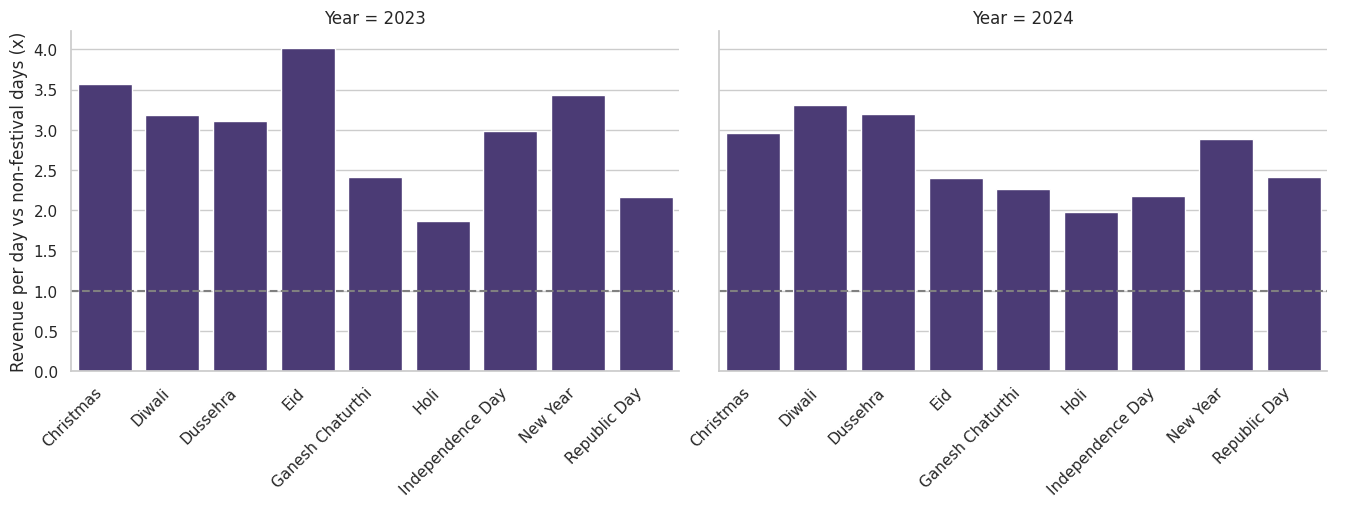

In [17]:
plot_df = fest.reset_index()
plot_df = plot_df[plot_df["Festival"] != "None"]

g = sns.catplot(data=plot_df, x="Festival", y="Uplift_vs_non_festival_x", col="Year",
                kind="bar", height=4.5, aspect=1.5)
g.set_xticklabels(rotation=45, ha="right")
g.set_axis_labels("", "Revenue per day vs non-festival days (x)")
for a in g.axes.flat:
    a.axhline(1, color="grey", linestyle="--")
plt.show()

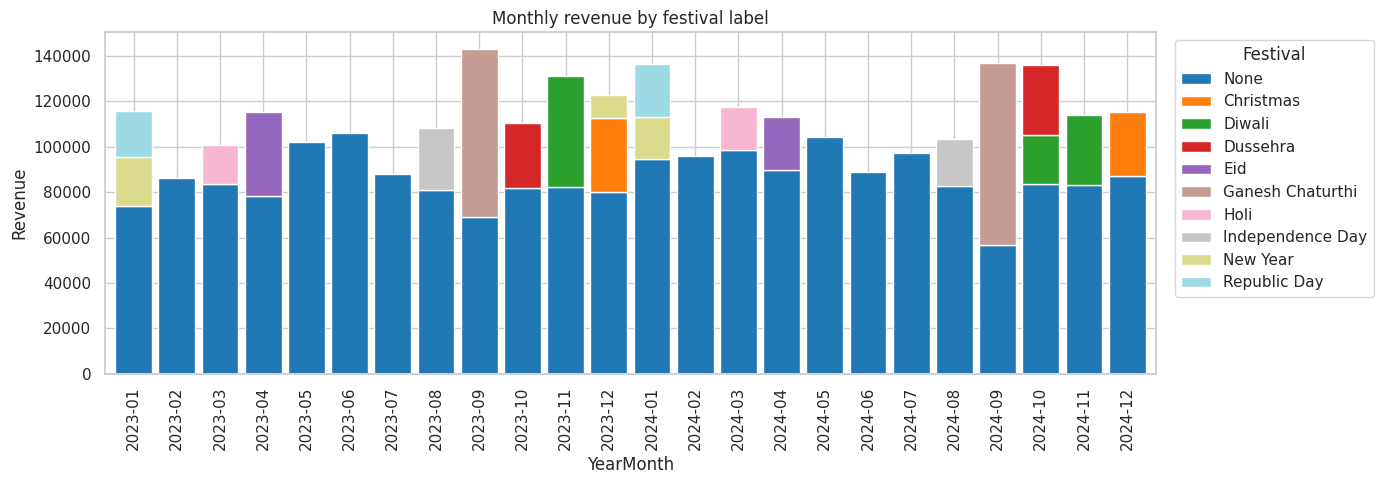

Festival      Diwali  Dussehra      None
Year Month                              
2023 10         0.00 28,659.71 81,779.49
     11    48,975.83      0.00 82,408.40
2024 10    21,930.77 30,857.80 83,432.58
     11    31,207.18      0.00 83,004.49

In [18]:
# Monthly revenue split by festival label
stack = (df.pivot_table(index="YearMonth", columns="Festival", values="Total_Bill", aggfunc="sum")
           .fillna(0))
stack = stack[["None"] + [c for c in stack.columns if c != "None"]]

ax = stack.plot.bar(stacked=True, figsize=(14, 5), width=0.85, colormap="tab20")
ax.set_title("Monthly revenue by festival label")
ax.set_ylabel("Revenue")
ax.legend(title="Festival", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

oct_nov = (df[df["Month"].isin([10, 11])]
           .pivot_table(index=["Year", "Month"], columns="Festival", values="Total_Bill", aggfunc="sum")
           .fillna(0))
oct_nov

**Reading**
- Festival days generate more revenue per day than ordinary days; Ganesh Chaturthi is the largest single festival bucket in both years.
- **Diwali moves:** November in 2023, spread over October–November in 2024. Combined with Dussehra, this is why October 2024 is high and November 2024 is lower than in 2023.
- Revenue on non-festival days is comparatively steady across months, so much of the visible seasonality follows the festival calendar rather than a fixed seasonal cycle. With two years of data this remains an observation, not a proven cause.

## 9. Promotion & margin

Festival and promotion overlap heavily (many promotions are festival promotions), so their effects **cannot be separated** with this data. This section focuses on what promotion costs in margin.

In [19]:
cols = ["Revenue", "Profit", "Margin_%", "Orders", "AOV", "Units_per_Order"]

promo_tbl = kpi_table("Promotion_Applied")[cols]
promo_tbl["Revenue_%"] = promo_tbl["Revenue"] / promo_tbl["Revenue"].sum() * 100
display(promo_tbl)

promo_type = kpi_table("Promotion_Type")[cols]
promo_type["Revenue_%"] = promo_type["Revenue"] / promo_type["Revenue"].sum() * 100
display(promo_type)

df["Discount_Band"] = pd.cut(df["Discount_Percentage"], bins=[-0.01, 0, 10, 20, 30.01],
                             labels=["0%", "0–10%", "10–20%", "20–30%"])
kpi_table("Discount_Band")[["Revenue", "Margin_%", "AOV", "Units_per_Order"]]

,Revenue,Profit,Margin_%,Orders,AOV,Units_per_Order,Revenue_%
Promotion_Applied,,,,,,,
No,"1,895,258.19","852,104.99",44.96,4762,398.00,6.25,70.43
Yes,"795,547.86","291,632.56",36.66,1814,438.56,7.32,29.57


,Revenue,Profit,Margin_%,Orders,AOV,Units_per_Order,Revenue_%
Promotion_Type,,,,,,,
Clearance,"93,019.94","26,763.46",28.77,304,305.99,5.92,3.46
Combo,"70,374.42","27,628.43",39.26,174,404.45,6.87,2.62
Festival,"384,456.50","140,322.01",36.50,689,557.99,9.08,14.29
Flash Sale,"38,553.38","12,572.46",32.61,116,332.36,5.89,1.43
None,"1,895,258.19","852,104.99",44.96,4762,398.00,6.25,70.43
Weekend,"209,143.62","84,346.20",40.33,531,393.87,6.31,7.77


,Revenue,Margin_%,AOV,Units_per_Order
Discount_Band,,,,
0%,"1,624,031.07",45.41,352.90,5.49
0–10%,"578,455.85",41.49,210.04,3.34
10–20%,"399,838.53",35.57,287.45,4.93
20–30%,"88,480.60",27.21,213.72,4.15


In [20]:
# September margin dilution: margin gap vs other months, and the profit it represents
mgn = df.groupby(["Year", "Is_Sep"]).agg(Revenue=("Total_Bill", "sum"), Profit=("Profit", "sum"))
mgn["Margin_%"] = mgn["Profit"] / mgn["Revenue"] * 100
display(mgn)

other_margin = mgn.xs(False, level="Is_Sep")["Margin_%"]
sep_m = mgn.xs(True, level="Is_Sep").copy()
sep_m["Profit_at_normal_margin"] = sep_m["Revenue"] * other_margin / 100
sep_m["Margin_dilution_cost"] = sep_m["Profit_at_normal_margin"] - sep_m["Profit"]

# September vs the average of the other 11 months
other = mgn.xs(False, level="Is_Sep")
sep_m["Revenue_vs_avg_month_%"] = (sep_m["Revenue"] / (other["Revenue"] / 11) - 1) * 100
sep_m["Profit_vs_avg_month_%"] = (sep_m["Profit"] / (other["Profit"] / 11) - 1) * 100
sep_m

Revenue     Profit  Margin_%
Year Is_Sep                                  
2023 False  1,187,295.03 506,704.00     42.68
     True     143,285.02  58,710.47     40.97
2024 False  1,223,382.74 522,440.16     42.70
     True     136,843.26  55,882.92     40.84

,Revenue,Profit,Margin_%,Profit_at_normal_margin,Margin_dilution_cost,Revenue_vs_avg_month_%,Profit_vs_avg_month_%
Year,,,,,,,
2023,"143,285.02","58,710.47",40.97,"61,150.00","2,439.53",32.75,27.45
2024,"136,843.26","55,882.92",40.84,"58,438.31","2,555.39",23.04,17.66


**Reading:** September margin is ≈ 1.8 percentage points below other months, a dilution worth roughly 2.5k profit per year. Profit still rises less than revenue (profit vs an average month: ≈ +27% in 2023 and ≈ +18% in 2024, against revenue ≈ +33% and ≈ +23%).

## 10. Category & store performance

,Revenue,Revenue_%,Profit,Margin_%,AOV,Units_per_Order
Category,,,,,,
Cakes,"894,754.35",33.25,"340,117.85",38.01,468.21,1.43
Indian Bakery,"648,365.37",24.10,"322,789.90",49.79,253.56,4.52
Dairy & Spreads,"374,442.29",13.92,"127,577.49",34.07,133.21,2.06
Pastry & Sweet,"295,173.31",10.97,"142,207.31",48.18,103.32,2.49
Beverages,"225,372.08",8.38,"96,244.64",42.70,84.95,1.86
Bread & Daily,"163,655.34",6.08,"72,483.58",44.29,71.19,3.11
Savoury Bakery,"89,043.31",3.31,"42,316.78",47.52,88.16,3.70


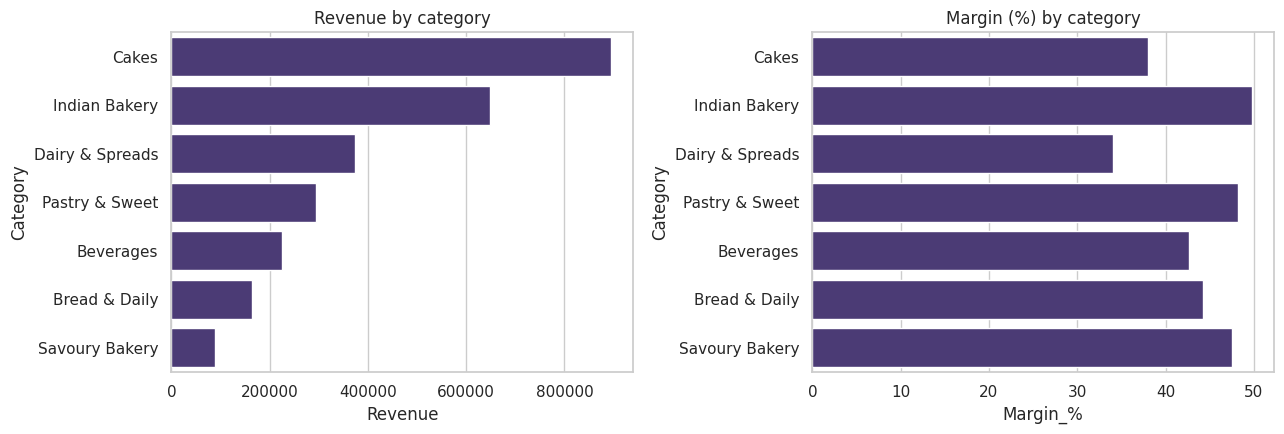

In [21]:
cat_perf = kpi_table("Category").sort_values("Revenue", ascending=False)
cat_perf["Revenue_%"] = cat_perf["Revenue"] / cat_perf["Revenue"].sum() * 100
display(cat_perf[["Revenue", "Revenue_%", "Profit", "Margin_%", "AOV", "Units_per_Order"]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=cat_perf["Revenue"], y=cat_perf.index, ax=ax[0])
ax[0].set_title("Revenue by category")
sns.barplot(x=cat_perf["Margin_%"], y=cat_perf.index, ax=ax[1])
ax[1].set_title("Margin (%) by category")
plt.tight_layout()
plt.show()

Revenue     Profit  Margin_%  Orders    AOV
Year Store_ID                                               
2023 ST01     455,901.19 193,529.36     42.45    1104 412.95
     ST02     439,089.86 186,077.27     42.38    1042 421.39
     ST03     435,589.00 185,807.84     42.66    1062 410.16
2024 ST01     483,366.29 205,949.38     42.61    1156 418.14
     ST02     451,799.26 192,068.78     42.51    1108 407.76
     ST03     425,060.45 180,304.92     42.42    1104 385.02

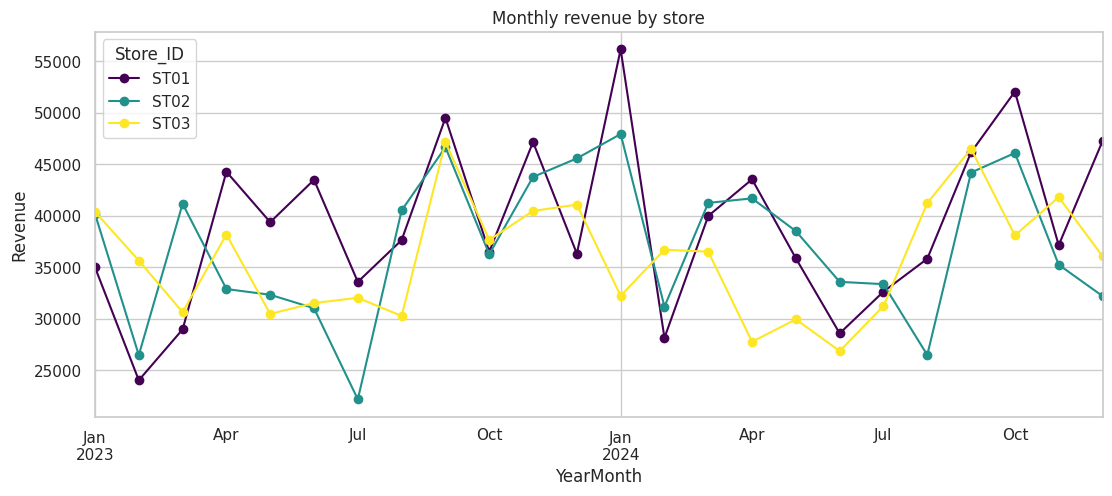

In [22]:
store_perf = kpi_table(["Year", "Store_ID"])
display(store_perf[["Revenue", "Profit", "Margin_%", "Orders", "AOV"]])

store_month = df.groupby(["YearMonth", "Store_ID"])["Total_Bill"].sum().unstack("Store_ID")
ax = store_month.plot(marker="o", figsize=(13, 5), colormap="viridis")
ax.set_title("Monthly revenue by store")
ax.set_ylabel("Revenue")
plt.show()

**Reading:** compare each category's revenue rank with its margin rank — a large category is not necessarily the most profitable. The store chart highlights the **ST02 dip in August 2024**; investigate it (opening hours, stock-outs, local events) before drawing store-level conclusions.

## 11. Waste & stock (group level)

Stock columns are group-level aggregates (Section 3), so waste is computed on a **Date × Store × Product** table, never by summing rows.
For the ≈ 3% of groups with inconsistent `Units_Produced`, the **maximum** is used as a working assumption.

In [23]:
grp = df.groupby(key).agg(
    Category=("Category", "first"),
    Revenue=("Total_Bill", "sum"),
    Profit=("Profit", "sum"),
    Produced_min=("Units_Produced", "min"),
    Produced_max=("Units_Produced", "max"),
    Sold=("Units_Sold", "first"),
    Cost=("Cost_Price", "mean"),
).reset_index()

inconsistent = grp["Produced_min"] != grp["Produced_max"]
print(f"Groups: {len(grp):,} | inconsistent Units_Produced: {inconsistent.sum():,} ({inconsistent.mean():.1%})")

grp["Produced"] = grp["Produced_max"]
grp["Unsold"] = grp["Produced"] - grp["Sold"]
grp["Waste_Cost"] = grp["Unsold"] * grp["Cost"]
grp["Year"] = grp["Date"].dt.year
grp["Month"] = grp["Date"].dt.month


def waste_table(by):
    t = grp.groupby(by).agg(Produced=("Produced", "sum"), Sold=("Sold", "sum"),
                            Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
                            Waste_Cost=("Waste_Cost", "sum"))
    t["Waste_%"] = (t["Produced"] - t["Sold"]) / t["Produced"] * 100
    t["Adj_Margin_%"] = (t["Profit"] - t["Waste_Cost"]) / t["Revenue"] * 100
    return t


waste_cat = waste_table("Category").sort_values("Waste_%", ascending=False)
waste_cat

Groups: 16,563 | inconsistent Units_Produced: 549 (3.3%)


,Produced,Sold,Revenue,Profit,Waste_Cost,Waste_%,Adj_Margin_%
Category,,,,,,,
Cakes,4710,2740,"894,754.35","340,117.85","418,323.78",41.83,-8.74
Beverages,7722,4923,"225,372.08","96,244.64","73,840.31",36.25,9.94
Dairy & Spreads,8951,5801,"374,442.29","127,577.49","155,557.91",35.19,-7.47
Pastry & Sweet,10360,7124,"295,173.31","142,207.31","69,949.07",31.24,24.48
Indian Bakery,15864,11559,"648,365.37","322,789.90","119,403.26",27.14,31.37
Bread & Daily,9644,7140,"163,655.34","72,483.58","45,261.81",25.96,16.63
Savoury Bakery,4701,3740,"89,043.31","42,316.78","12,007.55",20.44,34.04


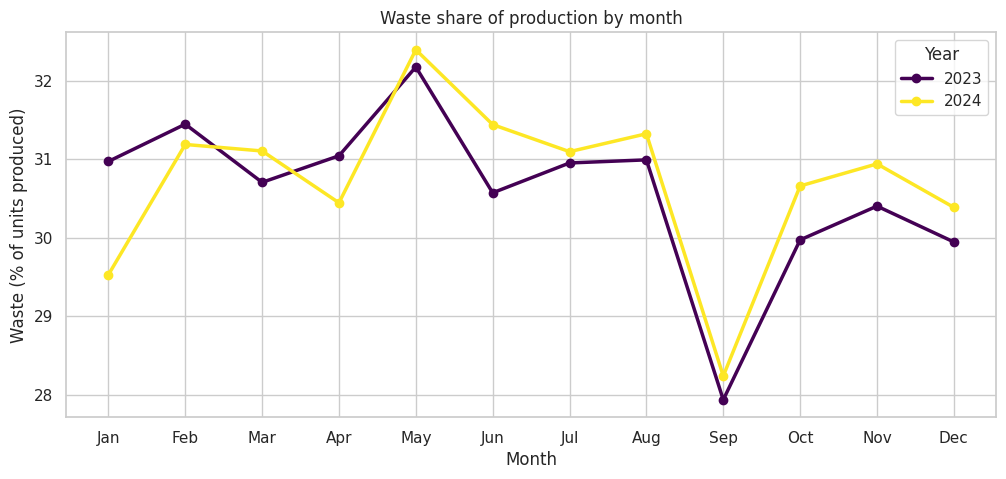

Waste_%  Waste_Cost    Profit  Adj_Margin_%
Year Month                                             
2023 1        30.97   40,373.17 48,227.52          6.80
     2        31.44   30,076.50 38,212.33          9.44
     3        30.70   34,771.50 43,348.61          8.51
     4        31.04   38,589.24 48,375.45          8.48
     5        32.17   37,003.93 44,589.19          7.42
     6        30.57   35,149.83 46,454.44         10.66
     7        30.95   29,008.94 38,623.58         10.95
     8        30.99   37,077.44 46,541.10          8.73
     9        27.94   42,641.22 58,710.47         11.21
     10       29.97   36,721.10 46,104.17          8.50
     11       30.40   43,525.03 54,329.76          8.22
     12       29.95   38,577.34 51,897.85         10.83
2024 1        29.53   42,957.62 57,222.44         10.47
     2        31.19   32,463.67 42,080.81         10.01
     3        31.10   41,700.92 49,569.12          6.68
     4        30.44   37,633.15 47,825.45          9.02
     5        32.39   36,778.69 45,099.96          7.97
     6        31.44   32,267.40 38,731.54          7.26
     7        31.09   33,165.71 42,585.55          9.68
     8        31.32   36,142.48 43,881.34          7.47
     9        28.24   40,356.07 55,882.92         11.35
     10       30.66   42,751.93 56,450.86         10.06
     11       30.94   37,212.51 48,752.54         10.10
     12       30.39   37,398.30 50,240.55         11.11

In [24]:
waste_month = waste_table(["Year", "Month"])

ax = waste_month["Waste_%"].unstack("Year").plot(marker="o", linewidth=2.5, colormap="viridis")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.set_title("Waste share of production by month")
ax.set_ylabel("Waste (% of units produced)")
plt.show()

waste_month[["Waste_%", "Waste_Cost", "Profit", "Adj_Margin_%"]]

_Interpret after running:_ which categories carry the highest waste, whether waste peaks in the festival-heavy months, and how much waste cost reduces the margin (`Adj_Margin_%` vs `Margin_%`).

## 12. Conclusions & recommendations

**What the data shows**
- Overall performance is stable (≈ +2% revenue and profit year-on-year, margin ≈ 42.5%); the main variation is seasonal and festival-driven.
- The September peak (+32% vs August in both years) coincides with Ganesh Chaturthi and a near-doubling of promotion intensity. It is broad-based across categories and stores and comes with larger baskets at a lower revenue per unit.
- Festival timing shifts between years (e.g. Diwali), so month-based comparisons can mislead.
- Promotion-heavy periods dilute margin by ≈ 1.8 pp.

**Recommendations (based on observed patterns, not proven causes)**
1. **Plan production, stock and staffing around the festival calendar**, not only calendar months — start preparation before Ganesh Chaturthi.
2. **Prioritise high-growth categories** for the peak (Bread & Daily, Beverages, Dairy & Spreads) alongside the large ones (Cakes, Indian Bakery).
3. **Review promotion design.** Test targeted or bundle offers instead of broad discounts to protect margin, and measure them against non-promoted festival days.
4. **Encourage bigger baskets** (bundles, multi-buy) since basket size is the most consistent driver of the September lift.
5. **Investigate store-level anomalies** such as ST02 in August 2024.
6. **Track waste at group level** and tie production planning to expected festival demand.

## 13. Limitations

- **Two annual cycles only** — seasonality is an indication, not a proven pattern.
- **Festival and promotion overlap**, so their individual effects cannot be separated; findings are associations, not causal effects.
- **Festival labels cover different numbers of days** per month, which affects monthly sums; per-day comparisons (Section 8) partly address this.
- **≈ 3.3% of groups** have inconsistent `Units_Produced`; waste figures use the maximum value as an assumption.
- **The dataset may be synthetic**, so patterns can be cleaner than in real retail data.
- **Currency is not specified**; values are in the dataset's own currency unit.

## Optional extensions
Weekday and hour-of-day patterns · loyalty and customer-segment value · weather and temperature · customer ratings · customer retention (repeat purchases).